In [ ]:
# Assignment 1 - Notebook setup (imports, paths, NLTK download)

from pathlib import Path
import sys
import nltk
import pandas as pd
import numpy as np

# Project paths (works on your machine as long as the folder stays the same)
ROOT = Path(r"E:\JYU\NLP\NLP")
A1_DIR = ROOT / "Assignment 1"
DATA_DIR = A1_DIR / "data"
RESULTS_DIR = A1_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("ROOT:", ROOT)
print("DATA_DIR exists:", DATA_DIR.exists())
print("RESULTS_DIR exists:", RESULTS_DIR.exists())

# NLTK resources used in basic NLP assignments
nltk.download("punkt")
nltk.download("stopwords")

Python: 3.10.11
ROOT: E:\JYU\NLP\NLP
DATA_DIR exists: True
RESULTS_DIR exists: True


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hasan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hasan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [ ]:
# Basic Text Definition and Sentence + Word Tokenization

from nltk.tokenize import sent_tokenize, word_tokenize

text = """
Natural Language Processing (NLP) is a field of Artificial Intelligence.
It focuses on enabling computers to understand and process human language.
This is our first assignment in the NLP course.
"""

# Sentence tokenization
sentences = sent_tokenize(text)

# Word tokenization
words = word_tokenize(text)

print("Sentences:")
for s in sentences:
    print("-", s)

print("\nTotal sentences:", len(sentences))
print("\nTotal words:", len(words))
print("\nWords:")
print(words)

Sentences:
- 
Natural Language Processing (NLP) is a field of Artificial Intelligence.
- It focuses on enabling computers to understand and process human language.
- This is our first assignment in the NLP course.

Total sentences: 3

Total words: 35

Words:
['Natural', 'Language', 'Processing', '(', 'NLP', ')', 'is', 'a', 'field', 'of', 'Artificial', 'Intelligence', '.', 'It', 'focuses', 'on', 'enabling', 'computers', 'to', 'understand', 'and', 'process', 'human', 'language', '.', 'This', 'is', 'our', 'first', 'assignment', 'in', 'the', 'NLP', 'course', '.']


In [ ]:
# Stopword Removal

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [w for w in words if w.lower() not in stop_words and w.isalpha()]

print("Total words before stopword removal:", len(words))
print("Total words after stopword removal:", len(filtered_words))
print("\nFiltered words:")
print(filtered_words)

Total words before stopword removal: 35
Total words after stopword removal: 18

Filtered words:
['Natural', 'Language', 'Processing', 'NLP', 'field', 'Artificial', 'Intelligence', 'focuses', 'enabling', 'computers', 'understand', 'process', 'human', 'language', 'first', 'assignment', 'NLP', 'course']


In [ ]:
# Word Frequency Analysis

from collections import Counter

word_freq = Counter(filtered_words)

print("Word Frequencies:")
for word, freq in word_freq.items():
    print(f"{word}: {freq}")

most_common = word_freq.most_common(5)

print("\nTop 5 Most Frequent Words:")
for word, freq in most_common:
    print(f"{word}: {freq}")

Word Frequencies:
Natural: 1
Language: 1
Processing: 1
NLP: 2
field: 1
Artificial: 1
Intelligence: 1
focuses: 1
enabling: 1
computers: 1
understand: 1
process: 1
human: 1
language: 1
first: 1
assignment: 1
course: 1

Top 5 Most Frequent Words:
NLP: 2
Natural: 1
Language: 1
Processing: 1
field: 1


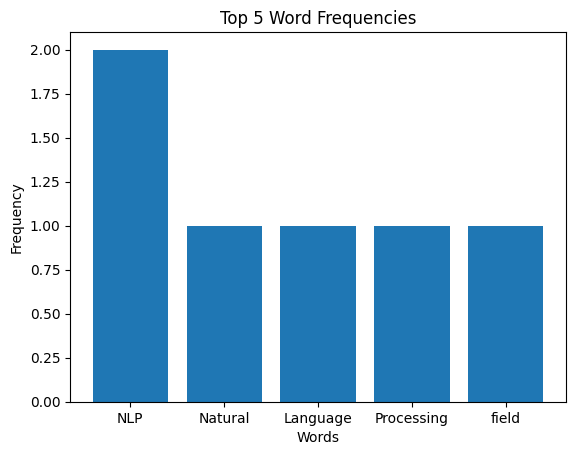

In [ ]:
# Word Frequency Visualization (Bar Chart)

import matplotlib.pyplot as plt

top_words = word_freq.most_common(5)
words_plot = [w[0] for w in top_words]
freq_plot = [w[1] for w in top_words]

plt.figure()
plt.bar(words_plot, freq_plot)
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 5 Word Frequencies")
plt.show()

In [ ]:
# Save Word Frequency Results to File

output_file = RESULTS_DIR / "A1_word_frequencies.txt"

with open(output_file, "w", encoding="utf-8") as f:
    f.write("Assignment 1 - Word Frequency Results\n")
    f.write("=" * 40 + "\n\n")
    for word, freq in word_freq.items():
        f.write(f"{word}: {freq}\n")

print("Results saved to:", output_file)


Results saved to: E:\JYU\NLP\NLP\Assignment 1\results\A1_word_frequencies.txt


In [ ]:
# Unigram and Bigram Language Model (Counts + MLE Probabilities)

from collections import Counter, defaultdict

# Use lowercase word tokens, keep only alphabetic tokens for a clean LM
lm_tokens = [w.lower() for w in words if w.isalpha()]

# Add sentence boundary markers (simple LM setup)
lm_seq = ["<s>"] + lm_tokens + ["</s>"]

# Unigram counts
uni_counts = Counter(lm_seq)

# Bigram counts
bi_counts = Counter(zip(lm_seq[:-1], lm_seq[1:]))

# Total tokens for unigram probabilities
N = sum(uni_counts.values())

def p_unigram(w: str) -> float:
    return uni_counts[w] / N

def p_bigram(w_prev: str, w: str) -> float:
    # MLE: P(w | w_prev) = count(w_prev, w) / count(w_prev)
    return bi_counts[(w_prev, w)] / uni_counts[w_prev] if uni_counts[w_prev] > 0 else 0.0

print("Top 10 unigrams:", uni_counts.most_common(10))
print("Top 10 bigrams:", bi_counts.most_common(10))

# Example probability calculations (as required in the proposal)
test_unigrams = ["nlp", "language", "processing", "<s>", "</s>"]
print("\nUnigram probabilities:")
for t in test_unigrams:
    print(t, "->", round(p_unigram(t), 4))

test_bigrams = [("<s>", "natural"), ("natural", "language"), ("language", "processing"), ("processing", "</s>")]
print("\nBigram probabilities:")
for a, b in test_bigrams:
    print((a, b), "->", round(p_bigram(a, b), 4))

Top 10 unigrams: [('language', 2), ('nlp', 2), ('is', 2), ('<s>', 1), ('natural', 1), ('processing', 1), ('a', 1), ('field', 1), ('of', 1), ('artificial', 1)]
Top 10 bigrams: [(('<s>', 'natural'), 1), (('natural', 'language'), 1), (('language', 'processing'), 1), (('processing', 'nlp'), 1), (('nlp', 'is'), 1), (('is', 'a'), 1), (('a', 'field'), 1), (('field', 'of'), 1), (('of', 'artificial'), 1), (('artificial', 'intelligence'), 1)]

Unigram probabilities:
nlp -> 0.0625
language -> 0.0625
processing -> 0.0312
<s> -> 0.0312
</s> -> 0.0312

Bigram probabilities:
('<s>', 'natural') -> 1.0
('natural', 'language') -> 1.0
('language', 'processing') -> 0.5
('processing', '</s>') -> 0.0
